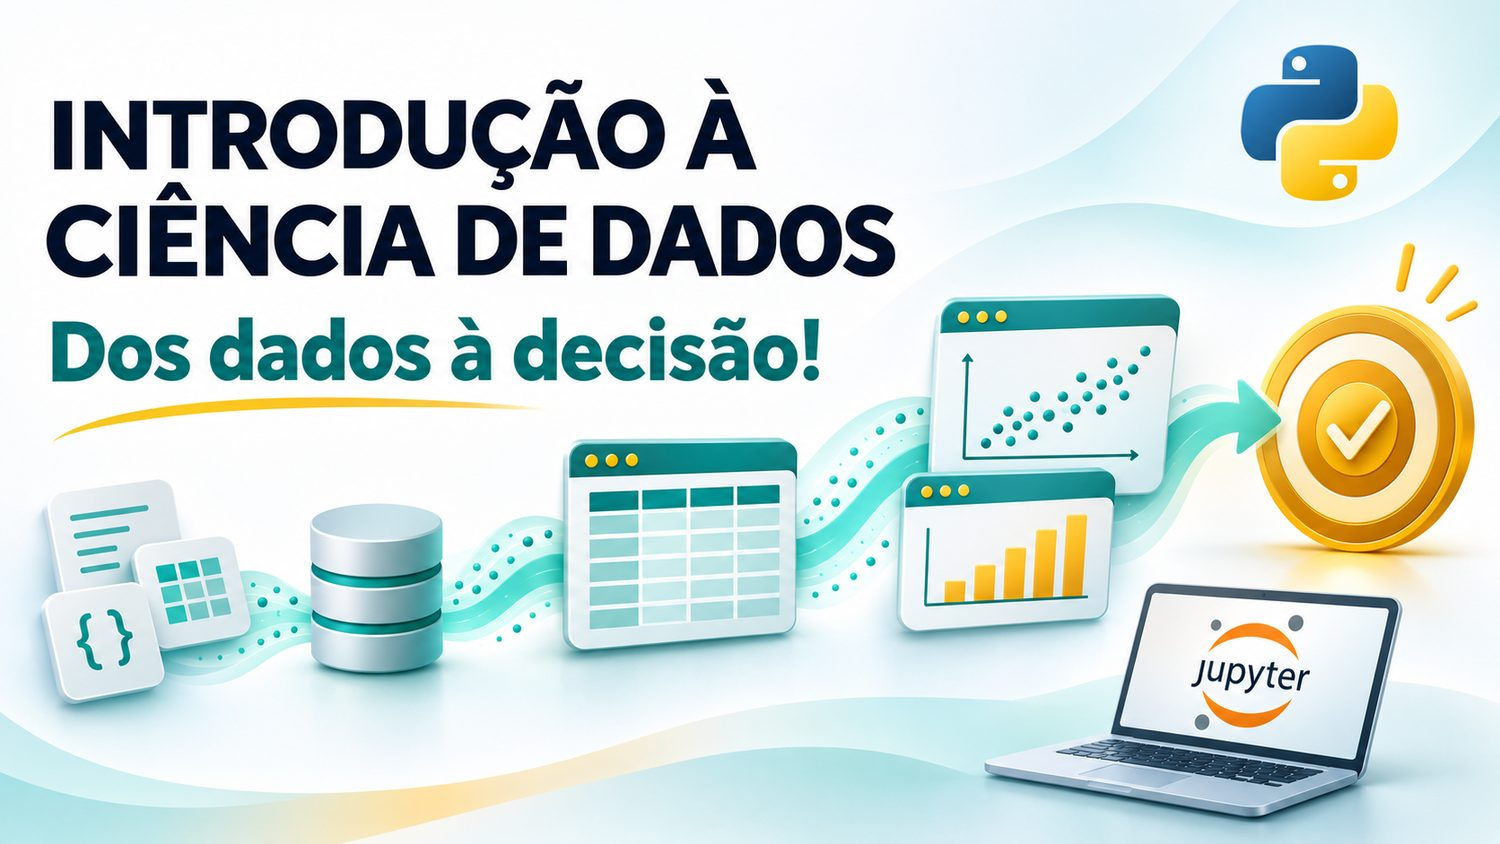

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_4_preparar_os_dados/06_Pipelines_sem_Fuga_de_Informacao.ipynb)

# Capítulo 6 – *Pipelines* sem fuga de informação

Imputar, mudar a escala, codificar, treinar: são quatro passos, cada um com o seu `fit` e o seu `transform`, e todos têm de aprender só com o treino. Feitos à mão, basta um engano para o teste deixar de ser independente. Este capítulo mostra quanto pode custar esse engano e como o evitar, juntando todos os passos num único objeto.

> **Objetivos:** definir fuga de informação e reconhecer as suas formas mais comuns; mostrar com uma experiência que uma fuga pode fabricar um modelo que não existe; construir um *pipeline* com passos diferentes para colunas numéricas, ordinais e nominais; treinar, avaliar e usar o *pipeline* num caso novo; aplicar uma lista de verificação antes de confiar num resultado.

**Pré-requisitos:** capítulos 1 a 5 deste módulo. Mais exemplos de *pipelines* em [Scikit-Learn: aplicações](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_05_ScikitLearn_Aplicacoes.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_carros(n=3000, semente=17):
    """Gera anúncios de carros usados de um stand fictício (dados sintéticos; as marcas são inventadas)."""
    rng = np.random.default_rng(semente)
    segmentos = {"citadino": (11000, 75), "utilitário": (15000, 100), "familiar": (21000, 130),
                 "SUV": (27000, 150), "monovolume": (23000, 125), "desportivo": (38000, 240)}
    marcas = {"Alba": 1.00, "Boreal": 0.92, "Cimo": 1.08, "Dueto": 0.95, "Estela": 1.30, "Faro": 1.00,
              "Gávea": 0.88, "Hera": 1.45, "Ípsilon": 1.05, "Jade": 0.97, "Kappa": 1.60, "Lume": 0.90}
    frequencia = np.array([18, 16, 14, 12, 9, 9, 7, 5, 4, 3, 2, 1], dtype=float)
    segmento = rng.choice(list(segmentos), n, p=[0.24, 0.28, 0.18, 0.18, 0.08, 0.04])
    marca = rng.choice(list(marcas), n, p=frequencia / frequencia.sum())
    ano = rng.integers(2008, 2026, n)
    idade = 2026 - ano
    km = (idade * 14000 * rng.lognormal(0, 0.35, n) + rng.uniform(500, 6000, n)).round(-2)
    potencia = np.array([segmentos[s][1] for s in segmento]) * rng.normal(1, 0.12, n)
    prob_eletrico = np.clip((ano - 2016) * 0.03, 0, 0.25)
    sorteio = rng.random(n)
    combustivel = np.where(sorteio < prob_eletrico, "elétrico", np.where(sorteio < prob_eletrico + 0.15, "híbrido",
                           np.where(sorteio < prob_eletrico + 0.55, "gasóleo", "gasolina")))
    caixa_velocidades = np.where(rng.random(n) < 0.25 + 0.4 * (combustivel == "elétrico"), "automática", "manual")
    niveis = np.array(["mau", "razoável", "bom", "excelente"])
    estado = niveis[np.clip(rng.normal(2.2 - 0.06 * idade, 0.8, n).round(), 0, 3).astype(int)]
    fator_estado = pd.Series(estado).map({"mau": 0.78, "razoável": 0.92, "bom": 1.0, "excelente": 1.08}).to_numpy()
    ruido = rng.lognormal(0, 0.10, n)                      # o que o preço tem de «caro» ou de «barato» sem explicação
    preco = (np.array([segmentos[s][0] for s in segmento]) * np.array([marcas[m] for m in marca])
             * np.exp(-0.085 * idade) * np.exp(-km / 420000) * fator_estado
             * np.where(caixa_velocidades == "automática", 1.08, 1.0)
             * np.where(combustivel == "elétrico", 1.25, np.where(combustivel == "híbrido", 1.12, 1.0))
             * (potencia / np.array([segmentos[s][1] for s in segmento])) ** 0.4 * ruido)
    carros = pd.DataFrame({
        "marca": marca, "segmento": segmento, "ano": ano, "km": km, "potencia_cv": potencia.round(),
        "combustivel": combustivel, "caixa": caixa_velocidades, "estado": estado,
        "cor": rng.choice(["branco", "cinzento", "preto", "azul", "vermelho"], n), "preco": preco.round(-1)})
    nivel = pd.Series(estado).map({"mau": 0, "razoável": 1, "bom": 2, "excelente": 3}).to_numpy()
    z = (-0.2 + 0.75 * (nivel - 1.5) - 0.07 * idade + 0.7 * np.isin(segmento, ["SUV", "utilitário"])
         + 0.5 * (caixa_velocidades == "automática") - 5 * np.log(ruido))
    carros["vendido_30_dias"] = rng.random(n) < 1 / (1 + np.exp(-z))
    # Valores em falta: quem tem muitos quilómetros «esquece-se» mais vezes de os indicar
    carros.loc[rng.random(n) < 0.03 + 0.25 * (km > np.quantile(km, 0.8)), "km"] = np.nan
    carros.loc[rng.random(n) < 0.06, "potencia_cv"] = np.nan
    carros.loc[rng.random(n) < 0.05, "estado"] = np.nan
    return carros


carros = gerar_carros()
carros.head()

,marca,segmento,ano,km,potencia_cv,combustivel,caixa,estado,cor,preco,vendido_30_dias
0,Boreal,SUV,2019,127500.0,199.0,híbrido,automática,razoável,cinzento,15250.0,False
1,Gávea,citadino,2012,171200.0,67.0,gasolina,manual,bom,azul,1630.0,False
2,Gávea,familiar,2018,123900.0,116.0,gasóleo,automática,bom,preto,6670.0,True
3,Cimo,utilitário,2009,239000.0,98.0,gasolina,manual,bom,cinzento,2350.0,False
4,Boreal,citadino,2016,122600.0,51.0,gasóleo,manual,bom,branco,3080.0,False


## O que é uma fuga de informação

Há **fuga de informação** (*data leakage*) quando o modelo, durante o treino, tem acesso a informação que não terá quando for usado. O resultado é sempre o mesmo: um desempenho no teste melhor do que o real.

Já encontrámos várias formas ao longo do tutorial.

| Forma | Exemplo | Onde foi tratada |
| --- | --- | --- |
| **Atributo do futuro** | Usar a hora de chegada para prever se o paciente falta | Módulo 1, capítulo 2 |
| **Atributo que contém o alvo** | Codificar a marca pelo preço médio, incluindo o do próprio carro | Capítulo 5 |
| **Linhas repetidas** | O mesmo carro no treino e no teste | Capítulo 2 |
| **Tempo baralhado** | Treinar com dias posteriores aos de teste | Módulo 3, capítulo 6 |
| **Preparação antes da divisão** | Calcular medianas, escalas ou escolher atributos com todos os dados | Capítulos 3 e 4, e este |
| **Teste usado para escolher** | Comparar dez modelos no teste e comunicar o melhor | Capítulo 2 |

Nos capítulos 3 e 4 vimos que calcular uma mediana ou uma escala com todos os dados quase não mudava o resultado. Seria um erro concluir que a regra é um preciosismo. O exemplo seguinte mostra porquê.

## Uma fuga que fabrica um modelo

Vamos construir um conjunto de dados em que **não há nada para aprender**: 100 casos, 5 000 atributos de puro ruído e um alvo sorteado ao acaso. Qualquer modelo honesto deve acertar em cerca de metade dos casos.

O procedimento tem dois passos: escolher os 20 atributos mais associados ao alvo, e treinar um modelo com eles.

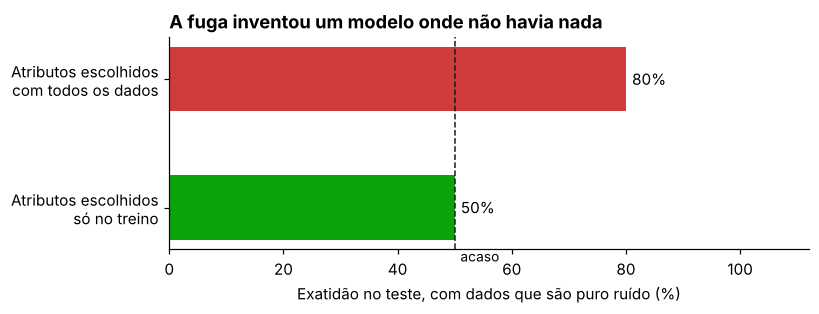

In [3]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(0)
ruido = rng.normal(size=(100, 5000))                 # 5 000 atributos sem qualquer significado
sorteio = rng.integers(0, 2, 100)                    # um alvo ao acaso

# ERRADO: escolher os atributos com todos os dados, e só depois dividir
escolhidos = SelectKBest(f_classif, k=20).fit(ruido, sorteio).transform(ruido)
A, B, ya, yb = train_test_split(escolhidos, sorteio, test_size=0.3, random_state=0)
com_fuga = LogisticRegression().fit(A, ya).score(B, yb)

# CERTO: dividir primeiro; a escolha dos atributos faz parte do que se aprende no treino
A, B, ya, yb = train_test_split(ruido, sorteio, test_size=0.3, random_state=0)
sem_fuga = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression()).fit(A, ya).score(B, yb)

fig, ax = plt.subplots(figsize=(7.5, 2.5))
barras = ax.barh(["Atributos escolhidos\ncom todos os dados", "Atributos escolhidos\nsó no treino"], [com_fuga * 100, sem_fuga * 100],
                 color=[MAU, BOM], height=0.5)
ax.bar_label(barras, fmt="%.0f%%", padding=4)
ax.axvline(50, color=TINTA, ls="--", lw=1)
ax.text(51, 1.42, "acaso", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xlabel("Exatidão no teste, com dados que são puro ruído (%)")
ax.set_title("A fuga inventou um modelo onde não havia nada")
plt.show()

Com a escolha feita antes da divisão, o modelo «acerta» numa percentagem muito acima do acaso, em dados que não contêm nenhuma relação. Com a escolha feita só no treino, o resultado volta para perto dos 50%, que é a verdade.

O que aconteceu? Entre 5 000 atributos de ruído, há sempre alguns que, por puro acaso, acompanham o alvo nestes 100 casos (módulo 3, capítulo 5). Ao escolhê-los com todos os dados, escolhemos os que acompanham o alvo **também nos casos de teste**. O teste confirmou uma coincidência que tinha sido selecionada a olhar para ele.

Num projeto real, este modelo seria apresentado, aprovado e posto a funcionar, e acertaria em metade dos casos.

> **Tudo o que é aprendido com os dados faz parte do modelo**, e tem de ser aprendido só com o treino: medianas, médias e desvios, listas de categorias, atributos escolhidos, valores extremos a remover.

## A solução: um *pipeline*

Um ***pipeline*** junta os passos de preparação e o modelo num só objeto, com um único `fit` e um único `predict`.

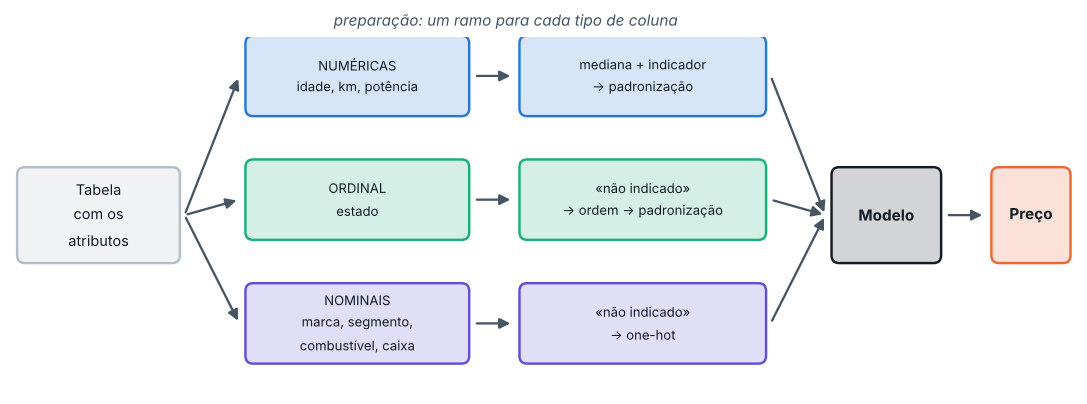

In [4]:
fig, ax = tela(14, 4.6, (12.5, 4.2))
caixa(ax, 0.1, 1.7, 2.1, 1.2, "Tabela\ncom os\natributos", CINZA, 9.5)
ramos = [(3.6, "NUMÉRICAS\nidade, km, potência", "mediana + indicador\n→ padronização", AZUL),
         (2.0, "ORDINAL\nestado", "«não indicado»\n→ ordem → padronização", VERDE),
         (0.4, "NOMINAIS\nmarca, segmento,\ncombustível, caixa", "«não indicado»\n→ one-hot", VIOLETA)]
for y, colunas, passos, cor in ramos:
    seta(ax, (2.28, 2.3), (3.0, y + 0.5))
    caixa(ax, 3.1, y, 2.9, 1.0, colunas, cor, 8.6)
    seta(ax, (6.08, y + 0.5), (6.6, y + 0.5))
    caixa(ax, 6.7, y, 3.2, 1.0, passos, cor, 8.6)
    seta(ax, (9.98, y + 0.5), (10.7, 2.3))
caixa(ax, 10.8, 1.7, 1.4, 1.2, "Modelo", TINTA, 10, True)
seta(ax, (12.28, 2.3), (12.8, 2.3))
caixa(ax, 12.9, 1.7, 1.0, 1.2, "Preço", LARANJA, 10, True)
ax.text(6.5, 4.75, "preparação: um ramo para cada tipo de coluna", ha="center", style="italic", color="#465463")
plt.show()

Cada tipo de coluna tem o seu tratamento (capítulos 3 a 5), e os três ramos juntam-se antes do modelo. No scikit-learn, os ramos são um `ColumnTransformer` e a sequência é um `Pipeline`.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

carros["idade"] = 2026 - carros["ano"]
numericas = ["idade", "km", "potencia_cv"]
ordinais = ["estado"]
nominais = ["marca", "segmento", "combustivel", "caixa"]
niveis = ["não indicado", "mau", "razoável", "bom", "excelente"]

preparacao = ColumnTransformer([
    ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                            ("escala", StandardScaler())]), numericas),
    ("ordinal", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="não indicado")),
                          ("ordem", OrdinalEncoder(categories=[niveis])),
                          ("escala", StandardScaler())]), ordinais),
    ("nominais", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="não indicado")),
                           ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=40))]), nominais)])

modelo = Pipeline([("preparacao", preparacao), ("vizinhos", KNeighborsRegressor(n_neighbors=8))])
modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacao', ...), ('vizinhos', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, d

Repara que a coluna `cor` não entra: não a pusemos em nenhuma lista. Num `ColumnTransformer`, as colunas que não são mencionadas ficam de fora.

O `pipeline` usa-se como qualquer modelo.

In [6]:
from sklearn.metrics import mean_absolute_error

X = carros[numericas + ordinais + nominais]            # a tabela em bruto, com valores em falta e texto
y = carros["preco"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=0)

modelo.fit(X_treino, y_treino)                         # aprende TUDO só com o treino: medianas, escalas, categorias e vizinhos
erro_teste = mean_absolute_error(y_teste, modelo.predict(X_teste))
print(f"Carros de teste com previsão: {len(X_teste)} de {len(X_teste)} | erro absoluto médio: {erro_teste:.0f} €")

Carros de teste com previsão: 750 de 750 | erro absoluto médio: 1335 €


Uma chamada a `fit` executa, por ordem, o `fit` e o `transform` de cada passo de preparação com os dados de treino, e depois treina o modelo. Uma chamada a `predict` aplica a cada passo só o `transform`, com o que foi aprendido no treino. Deixa de ser possível calcular uma mediana ou uma escala com o teste, porque o teste nunca passa por um `fit`.

Outras três vantagens:

- **prevê todos os carros**, incluindo os que têm valores em falta;
- **aceita um carro novo tal como chega**, sem ser preciso repetir a preparação à mão;
- **guarda-se e partilha-se como um só objeto**: quem usar o modelo aplica obrigatoriamente a mesma preparação.

In [7]:
carro_novo = pd.DataFrame([{"idade": 6, "km": np.nan, "potencia_cv": 110, "estado": "bom",
                            "marca": "Zénite", "segmento": "familiar", "combustivel": "híbrido", "caixa": "automática"}])
print(f"Preço proposto para um carro sem quilómetros indicados e de uma marca desconhecida: {modelo.predict(carro_novo)[0]:.0f} €")

Preço proposto para um carro sem quilómetros indicados e de uma marca desconhecida: 9150 €


O carro tem os quilómetros em falta e é de uma marca que o modelo nunca viu. O *pipeline* trata dos dois casos como foi decidido nos capítulos 3 e 5, e propõe um preço.

## Quanto valeu a preparação

Vamos comparar tudo o que o módulo ensinou, no mesmo conjunto de teste. Como o alvo é um preço, os modelos preveem o seu logaritmo (capítulo 4); o `TransformedTargetRegressor` trata de aplicar o logaritmo no treino e de o desfazer na previsão.

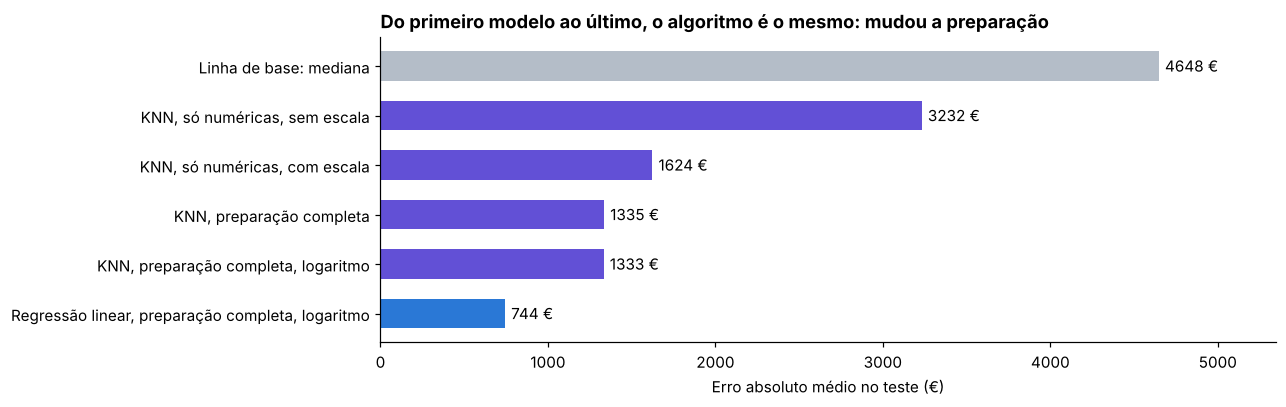

In [8]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression


def em_log(regressor):
    return TransformedTargetRegressor(regressor=regressor, func=np.log10, inverse_func=lambda v: 10 ** v)


so_numericas = ColumnTransformer([("numericas", SimpleImputer(strategy="median"), numericas)])
candidatos = {
    "Linha de base: mediana": DummyRegressor(strategy="median"),
    "KNN, só numéricas, sem escala": Pipeline([("p", so_numericas), ("m", KNeighborsRegressor(8))]),
    "KNN, só numéricas, com escala": Pipeline([("p", so_numericas), ("e", StandardScaler()), ("m", KNeighborsRegressor(8))]),
    "KNN, preparação completa": Pipeline([("p", preparacao), ("m", KNeighborsRegressor(8))]),
    "KNN, preparação completa, logaritmo": Pipeline([("p", preparacao), ("m", em_log(KNeighborsRegressor(8)))]),
    "Regressão linear, preparação completa, logaritmo": Pipeline([("p", preparacao), ("m", em_log(LinearRegression()))])}
erros = {nome: mean_absolute_error(y_teste, m.fit(X_treino, y_treino).predict(X_teste)) for nome, m in candidatos.items()}

fig, ax = plt.subplots(figsize=(10.5, 3.6))
barras = ax.barh(list(erros), list(erros.values()), color=[CINZA, VIOLETA, VIOLETA, VIOLETA, VIOLETA, AZUL], height=0.6)
ax.bar_label(barras, fmt="%.0f €", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(erros.values()) * 1.15)
ax.set_xlabel("Erro absoluto médio no teste (€)")
ax.set_title("Do primeiro modelo ao último, o algoritmo é o mesmo: mudou a preparação")
plt.show()

Lê as barras do KNN de cima para baixo. O algoritmo é sempre o mesmo, com os mesmos oito vizinhos. A escala reduz o erro para metade; juntar as categorias, bem codificadas, volta a reduzi-lo. A preparação valeu muito mais do que qualquer afinação do modelo teria valido.

A última barra lembra outra coisa: com os atributos certos, um modelo simples como a regressão linear bate o KNN por larga margem. Porque é que isso acontece, como se escolhe entre modelos e como se comparam com rigor são os temas do módulo 5.

Uma reserva: comparámos seis candidatos no teste, o que o capítulo 2 desaconselha. Aqui serve para ilustrar o efeito de cada passo. Num projeto, a comparação far-se-ia na validação, e só o escolhido iria ao teste.

## Antes de confiar num resultado

1. **A divisão foi a primeira coisa a ser feita?** Antes de qualquer cálculo que use os valores dos dados.
2. **A divisão imita o uso real?** Tempo, grupos e duplicados foram respeitados.
3. **Toda a preparação está dentro do *pipeline*?** Nada foi «arranjado» na tabela inteira antes.
4. **Cada atributo estará disponível no momento da previsão?** E com o mesmo significado.
5. **Algum atributo é o alvo disfarçado?** Um atributo que sozinho acerta quase tudo é suspeito.
6. **O modelo foi comparado com uma linha de base?** Incluindo a prática atual.
7. **O teste foi usado uma só vez?** As escolhas fizeram-se na validação.
8. **O resultado é bom de mais?** Se parece, quase sempre é uma fuga.

O último ponto é o melhor detetor. Um modelo que acerta 99% num problema difícil não é motivo de festa: é motivo para rever os sete pontos anteriores.

## Resumo do módulo

| Capítulo | Pergunta | Regra a reter |
| --- | --- | --- |
| 1. Aprender com dados | O que quer dizer aprender? | Definir a tarefa, a experiência e a medida de desempenho |
| 2. Treino, teste e linha de base | Como sei se o modelo presta? | Medir em dados que não participaram no treino, e comparar com uma linha de base |
| 3. Valores em falta | O que faço às células vazias? | Imputar com cuidado e guardar um indicador; remover linhas não resolve o dia da previsão |
| 4. Escalas | Porque é que o maior número manda? | Igualar as escalas para modelos de distâncias; logaritmo para variáveis assimétricas |
| 5. Categorias | Como transformo palavras em números? | *One-hot* para nominais; ordem verdadeira para ordinais |
| 6. *Pipelines* | Como evito enganar-me? | Tudo o que se aprende com os dados aprende-se no treino, dentro de um *pipeline* |

No CRISP-DM, este módulo é a fase de **preparação dos dados**, e a entrada na de **modelação**. O módulo 5 trata dos modelos e da forma de os avaliar.

## Exercícios

### `Exercício 1` – Há fuga?

Para cada procedimento, diz se há fuga de informação e como a corrigir:

1. Remover os valores extremos (preços acima do percentil 99 de todos os dados) e depois dividir em treino e teste.
2. Para prever se um cliente vai cancelar o contrato, usar o atributo «número de chamadas para a linha de cancelamento».
3. Dividir em treino e teste, e depois padronizar cada um dos dois com a sua própria média e desvio padrão.
4. Afinar o número de vizinhos com validação, e medir o modelo final no teste uma vez.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Há fuga: o percentil foi calculado com o teste. E há um problema maior: na prática, os carros caros vão continuar a chegar, e o teste deixou de os ter. O limite calcula-se no treino, e o teste fica como está.
2. Há fuga: o atributo é o alvo disfarçado, e só existe quando o cliente já decidiu cancelar. Retira-se.
3. Não é uma fuga no sentido habitual, mas está errado: o teste fica numa escala diferente da do treino. Usa-se a média e o desvio do treino nos dois.
4. Não há fuga. É o procedimento correto.

</details>

### `Exercício 2` – O teu *pipeline* de classificação

Constrói um *pipeline* para prever `vendido_30_dias`, com a mesma preparação e uma `LogisticRegression`. Divide com estratificação, compara com a linha de base e indica a exatidão no teste.

In [9]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.dummy import DummyClassifier

alvo = carros["vendido_30_dias"]
Xa, Xb, ya, yb = train_test_split(X, alvo, test_size=0.25, random_state=0, stratify=alvo)
classificador = Pipeline([("preparacao", preparacao), ("modelo", LogisticRegression(max_iter=2000))]).fit(Xa, ya)
base = DummyClassifier(strategy="most_frequent").fit(Xa, ya)
print(f"Linha de base: {base.score(Xb, yb):.1%} | pipeline: {classificador.score(Xb, yb):.1%}")
```

A linha de base acerta em cerca de 56% dos carros. O *pipeline* fica uns dez pontos acima. No capítulo 2, só com três atributos numéricos, o ganho era de dois ou três pontos: a diferença são o estado e o segmento, que agora o modelo consegue usar.

</details>

### `Exercício 3` – Repetir a experiência do ruído

Repete a experiência da fuga com 50 sorteios diferentes dos dados de ruído. Qual é a exatidão média de cada procedimento? E o que acontece à versão com fuga se houver 500 atributos em vez de 5 000?

In [10]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def experiencia(n_atributos, semente):
    r = np.random.default_rng(semente)
    ruido_, sorteio_ = r.normal(size=(100, n_atributos)), r.integers(0, 2, 100)
    e = SelectKBest(f_classif, k=20).fit(ruido_, sorteio_).transform(ruido_)
    A, B, ya, yb = train_test_split(e, sorteio_, test_size=0.3, random_state=0)
    fuga = LogisticRegression().fit(A, ya).score(B, yb)
    A, B, ya, yb = train_test_split(ruido_, sorteio_, test_size=0.3, random_state=0)
    certo = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression()).fit(A, ya).score(B, yb)
    return fuga, certo


for n in [500, 5000]:
    r = np.array([experiencia(n, s) for s in range(50)])
    print(f"{n} atributos → com fuga: {r[:, 0].mean():.0%} | sem fuga: {r[:, 1].mean():.0%}")
```

Sem fuga, a média fica nos 50%, como deve ser. Com fuga, fica muito acima, e mais ainda com 5 000 atributos do que com 500: quanto mais atributos há por onde escolher, mais coincidências fortes aparecem. É por isso que este erro é tão frequente em áreas com milhares de atributos e poucas observações, como a genética.

</details>

### `Exercício 4` – Trocar de modelo

Substitui o KNN do *pipeline* por uma `DecisionTreeRegressor(max_depth=8)`, sem mudar a preparação. Quanto dá no teste? Depois retira a padronização do ramo numérico. O resultado da árvore muda?

In [11]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.tree import DecisionTreeRegressor

arvore = Pipeline([("preparacao", preparacao), ("modelo", DecisionTreeRegressor(max_depth=8, random_state=0))]).fit(X_treino, y_treino)
print(round(mean_absolute_error(y_teste, arvore.predict(X_teste))), "€")

sem_escala = ColumnTransformer([("numericas", SimpleImputer(strategy="median", add_indicator=True), numericas),
                                ("ordinal", Pipeline([("i", SimpleImputer(strategy="constant", fill_value="não indicado")), ("o", OrdinalEncoder(categories=[niveis]))]), ordinais),
                                ("nominais", Pipeline([("i", SimpleImputer(strategy="constant", fill_value="não indicado")), ("h", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=40))]), nominais)])
arvore2 = Pipeline([("preparacao", sem_escala), ("modelo", DecisionTreeRegressor(max_depth=8, random_state=0))]).fit(X_treino, y_treino)
print(round(mean_absolute_error(y_teste, arvore2.predict(X_teste))), "€")
```

Trocar de modelo foi mudar uma linha. E a árvore dá o mesmo erro com e sem padronização, como o capítulo 4 previa: só faz perguntas do tipo «é maior do que…?», e a resposta não depende da unidade.

</details>

## Verifica o que aprendeste

- [ ] Sei definir fuga de informação e enumerar seis formas em que aparece.
- [ ] Sei explicar como a escolha de atributos antes da divisão fabrica um modelo a partir de ruído.
- [ ] Sei construir um `ColumnTransformer` com passos diferentes por tipo de coluna.
- [ ] Sei juntar a preparação e o modelo num `Pipeline`, treiná-lo e usá-lo num caso novo.
- [ ] Sei porque um *pipeline* impede as fugas na preparação.
- [ ] Sei a lista de oito verificações a fazer antes de confiar num resultado.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/compose.html
- https://scikit-learn.org/stable/common_pitfalls.html
- https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html
- https://en.wikipedia.org/wiki/Leakage_(machine_learning)